# Grevy's zebra body orientation during an escape response

A focal group of Grevy's zebra (*Equus grevyi*, $N = 18$) was recorded with an overhead drone at the Mpala Conservancy in Laikipia, Kenya: the body orientations come from the drone recordings of B. Koger, A. Deshpande, J. T. Kerby, J. M. Graving, B. R. Costelloe, and I. D. Couzin, "Quantifying the movement, behaviour and environmental context of group-living animals using drones and computer vision," *Journal of Animal Ecology* **92**(6), 1415-1433 (2023); [doi:10.1111/1365-2656.13904](https://doi.org/10.1111/1365-2656.13904). The first two flights captured baseline (grazing) behavior; the third flight contains a disturbance event in which a human observer approaches the group. Body orientation is available for each frame from automated tracking (body axis from the tail base to the neck base; tracked with DeepPoseKit, J. M. Graving et al., *eLife* **8**, e47994 (2019); [doi:10.7554/eLife.47994](https://doi.org/10.7554/eLife.47994)).

To reduce temporal autocorrelation, orientations are circularly averaged over
non-overlapping 300-frame windows (10 s at 30 Hz), giving approximately
independent observations. Each window is labeled
**pre-approach** (the pre-stimulus baseline) or
**post-approach** (the post-stimulus escape response), so the data
are repeated direction measurements nested within individuals.

**Scientific question.** Does the group's typical orientation change in response
to the stimulus, and how precisely do individuals orient? The hierarchical model
separates three complementary aspects of the response:

- a group-level shift in the mean direction ($\mu$);
- **between-individual alignment**: how tightly the individual mean directions
  cluster, summarized as a mean resultant length in $[0, 1]$;
- **within-individual concentration**: $\kappa$ per track, reported on a
  $[0, 1]$ scale via the Bessel ratio $R(\kappa) = I_1(\kappa)/I_0(\kappa)$.


The joint hierarchical von Mises model is fit with `brms` and the custom `unwrap_von_mises` family. Both mean direction and concentration have `PostStimulus` effects and individual `Track` intercept/slope effects.


## Setup

Follow the [R setup](../getting-started-r.md) page once, select the
**R (`ir`)** kernel, and run all cells in order. The setup cell checks
that the pinned packages and CmdStan are available; it stops with a
pointer to the setup page if the one-time setup has not been run.
Running the notebook records versions, diagnostics, inline PNGs, and
vector PDFs.


In [1]:
# Setup: check that this notebook's stack is available. The examples
# are verified against the pinned package set recorded in renv.lock, so
# this cell deliberately does not auto-install: an unpinned install
# could silently drift from the verified set. Run the one-time setup on
# the R setup page first (docs/getting-started-r.md).

required <- c("brms", "posterior", "loo", "circular", "ggplot2", "ragg", "arrow")
missing <- required[!vapply(required, requireNamespace, logical(1),
  quietly = TRUE)]
if (length(missing))
  stop("Missing R package(s): ", paste(missing, collapse = ", "),
       " - run the one-time setup on the R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

cmdstan_ok <- tryCatch(
  dir.exists(as.character(cmdstanr::cmdstan_path())),
  error = function(e) FALSE)
if (!cmdstan_ok)
  stop("cmdstanr/CmdStan is not available - run the one-time setup on the",
       " R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

In [2]:
suppressPackageStartupMessages({
    library(brms)
    library(posterior)
    library(loo)
    library(circular)
    library(ggplot2)
    library(arrow)
})

# The repository's R helpers (custom brms family + circular statistics)
# live next to the notebook; make them reachable regardless of the
# kernel's working directory.
repo_root <- if (file.exists(file.path("..", "R", "unwrap_family.R"))) ".." else
    if (file.exists(file.path("R", "unwrap_family.R"))) "." else
    stop("Run this notebook from notebooks_r/ or from the repository root.")
source(file.path(repo_root, "R", "unwrap_family.R"))
source(file.path(repo_root, "R", "unwrap_functions.R"))
source(file.path(repo_root, "notebooks_r", "zebra_posthoc.R"))
source(file.path(repo_root, "notebooks_r", "zebra_plots.R"))

# The figure code writes to the repository-relative figures directory.
FIG_DIR <- file.path(repo_root, "figures", "zebra_escape")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)
theme_set(theme_minimal(base_size = 12))

# Without X11/cairo (most server R installs) the default device cannot
# rasterise, so each figure renders to a PNG through ragg and displays
# inline; a vector PDF is saved alongside as the portable copy.
show_figure <- function(plot, name, width, height, res = 110) {
  file <- file.path(FIG_DIR, paste0(name, ".png"))
  ragg::agg_png(file, width = width, height = height, units = "in",
                res = res)
  print(plot)
  invisible(dev.off())
  IRdisplay::display_png(file = file)
  invisible(NULL)
}


SEED <- 42
set.seed(SEED)
quick_run <- Sys.getenv("UNWRAP_R_QUICK") == "1"
CHAINS <- 4L
# Hierarchical models need longer adaptation and more retained draws than
# the introductory GLM. Quick mode keeps the full data and model, shortening only
# sampling and Monte Carlo plotting/bootstrapping budgets.
ITER <- if (quick_run) 6000L else 8000L
WARMUP <- if (quick_run) 2250L else 3000L
ADAPT_DELTA <- 0.97
# The tighter adapt_delta protects the grouped concentration geometry;
# these are execution budgets, not a claim of verified convergence.

c(R = as.character(getRversion()),
  brms = as.character(packageVersion("brms")),
  cmdstanr = as.character(packageVersion("cmdstanr")),
  posterior = as.character(packageVersion("posterior")),
  loo = as.character(packageVersion("loo")),
  circular = as.character(packageVersion("circular")),
  ggplot2 = as.character(packageVersion("ggplot2")),
  ragg = as.character(packageVersion("ragg")),
  arrow = as.character(packageVersion("arrow")))


Loading required package: cmdstanr



This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /home/jake/.cmdstan/cmdstan-2.40.0



- CmdStan version: 2.40.0



R          brms      cmdstanr     posterior           loo 
      "4.5.3"      "2.23.0"       "0.9.0"       "1.7.1" "2.10.1.9000" 
     circular       ggplot2          ragg         arrow 
      "0.5.2"       "4.0.3"       "1.5.2"      "26.0.0"

## Figure style

Figures render inline and save vector PDFs under
`figures/zebra_escape/`. The condition colors match those of the
Python analysis. All angular calculations use radians and circular summaries.


In [3]:
save_figure <- function(plot, name, width = 8, height = 4) {
  ggsave(file.path(FIG_DIR, paste0(name, ".pdf")), plot,
         width = width, height = height)
  show_figure(plot, name, width, height)
}

# Same published source files as the Python loaders; keep their local
# checkout under the repository root, reachable from notebooks_r/ too.
# An existing checkout can be supplied through UNWRAP_DATA_ROOT.
data_root <- Sys.getenv("UNWRAP_DATA_ROOT",
                        unset = file.path(repo_root, "unwrap-data"))
ensure_data <- function(subdir) {
  target <- file.path(data_root, subdir)
  if (!dir.exists(target)) {
    if (!dir.exists(data_root)) {
      status <- system2("git", c("clone", "--depth", "1",
        "--filter=blob:none", "--sparse",
        "https://github.com/jgraving/unwrap-data.git", shQuote(data_root)))
      if (status != 0L) stop("Could not fetch the published study data.")
    }
    # Sparse checkout downloads only this study; later notebooks may add
    # their own subdirectory to the same checkout without replacing it.
    status <- system2("git", c("-C", shQuote(data_root),
                              "sparse-checkout", "add", subdir))
    if (status != 0L) stop("Could not materialize the study subdirectory.")
  }
  stopifnot(dir.exists(target))
  target
}


## 1. Load the block-averaged bearings

Read the same published `zebra_bearings_blocks.parquet` as the Python
loader. Each row is a non-overlapping 300-frame (10 s at 30 Hz)
circular average, $\operatorname{atan2}(\overline{\sin b},\overline{\cos b})$.
The published table already excludes tracks absent from either condition;
do not average the blocks again. `Track` labels the 18 individuals and
`PostStimulus` codes pre-approach (0) versus post-approach (1).


In [4]:
data_dir <- ensure_data("zebra_bearings")
data <- as.data.frame(arrow::read_parquet(file.path(data_dir,
                                              "zebra_bearings_blocks.parquet")))
needed <- c("Track", "Observation", "Condition", "HeadingRadians", "PostStimulus")
stopifnot(all(needed %in% names(data)), !anyNA(data[needed]))
data$Track <- factor(data$Track)
data$PostStimulus <- as.integer(data$PostStimulus)
data$HeadingRadians <- mod_circular(data$HeadingRadians)
condition_labels <- c("pre-approach", "post-approach")
condition_colors <- c("pre-approach" = "#E69F00", "post-approach" = "#7B3294")
data$condition <- factor(data$PostStimulus, levels = 0:1, labels = condition_labels)
stopifnot(nlevels(data$Track) == 18L,
          all(table(data$Track, data$PostStimulus) > 0),
          all(is.finite(data$HeadingRadians)))
head(data)


,Track,Observation,Condition,HeadingRadians,PostStimulus,condition
,<fct>,<chr>,<chr>,<dbl>,<int>,<fct>
1,observation088-0,observation088,pre-approach,1.324933,0,pre-approach
2,observation088-0,observation088,pre-approach,1.455568,0,pre-approach
3,observation088-0,observation088,pre-approach,1.578286,0,pre-approach
4,observation088-0,observation088,pre-approach,1.412140,0,pre-approach
5,observation088-0,observation088,pre-approach,1.778967,0,pre-approach
6,observation088-0,observation088,pre-approach,2.116859,0,pre-approach


## 2. Specify the joint model

Both submodels have the same fixed and random structure: `HeadingRadians ~ PostStimulus + (1 + PostStimulus | Track)` for the mean direction and `kappa ~ PostStimulus + (1 + PostStimulus | Track)` for the concentration.

Mean-direction priors: intercept `VonMises(0, 1e-6)`, stimulus
`VonMises(0, 2)`; independent individual intercept/slope deviations
`VonMises(0, kappa)` with separate `LogNormal(log(30), 0.5)` hyperpriors.
Concentration priors (pre-softplus): intercept
`Normal(inverse_softplus(2), 1)`, stimulus `Normal(0, 2)`, independent
Normal individual deviations with `HalfNormal(2)` scales. Explicit
concentration intercept coding prevents predictor centering.


In [5]:
# Preserve independent circular intercept and slope deviations. brms's
# ordinary (1 + PostStimulus | Track) mu term would impose Gaussian effects.
# Following the Rmd, represent them as nonlinear coefficient vectors.
form_vonmises <- bf(HeadingRadians ~ mu,
  nlf(mu ~ beta0 + bias0 + PostStimulus * bias1),
  beta0 ~ 1 + PostStimulus,
  bias0 ~ 0 + Track,
  bias1 ~ 0 + Track,
  kappa ~ 0 + Intercept + PostStimulus + (1 + PostStimulus || Track),
  family = unwrap_von_mises)

# One LogNormal(log(30), 0.5) hyperprior for each direction-effect vector,
# as in Python. Direct positive parameters need no softplus Jacobian.
stan_direction_priors <- stanvar(scode = "
  real<lower=0> kmu_intercept;
  real<lower=0> kmu_slope;
", block = "parameters") + stanvar(scode = "
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) {
      lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    }
    return lp;
  }
", block = "functions")
prior_vonmises <- (
  # The direction coefficients are unconstrained reals, matching the
  # Python twin's circ_mod parameterization: its von Mises coefficient
  # priors are periodic over the real line and carry no +-pi bounds.
  # Each coefficient's prior is its von Mises log density, added as an
  # explicit target term (the weak-kappa 1e-6 intercept term is
  # effectively flat over any 2*pi window; a uniform prior is NOT used:
  # bounded uniform boxes pin NUTS chains against the +-pi walls). The
  # generated Stan for this prior set is free of brms's default Gaussian
  # on the direction coefficients (verified at build time in the fit
  # cell).
  set_prior("target += unwrap_von_mises_lpdf(b_beta0[1] | 0, 1e-6)", check = FALSE) +
  set_prior("target += unwrap_von_mises_lpdf(b_beta0[2] | 0, 2)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_bias0 | 0, kmu_intercept)",
            check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_bias1 | 0, kmu_slope)",
            check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_intercept | log(30), 0.5)",
            check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_slope | log(30), 0.5)",
            check = FALSE) +
  prior("normal(log(exp(2) - 1), 1)", class = "b", dpar = "kappa",
        coef = "Intercept") +
  prior("normal(0, 2)", class = "b", dpar = "kappa",
        coef = "PostStimulus") +
  prior("normal(0, 2)", class = "sd", dpar = "kappa")
)
# EQUIVALENCE NOTE: || removes brms's default intercept/slope correlation;
# the Python priors are separate independent effects, with no LKJ term.
# Gaussian kappa effects use brms's non-centered parameterization and
# positive sd bounds turn normal(0, 2) into HalfNormal(2).
# The nonlinear mu vectors retain centered von Mises effects, not normal
# random effects. Verify their generated names/bounds/priors when baking.
prior_vonmises

prior,class,coef,group,resp,dpar,nlpar,lb,ub,tag,source
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"target += unwrap_von_mises_lpdf(b_beta0[1] | 0, 1e-6)",,,,,,,,,,user
"target += unwrap_von_mises_lpdf(b_beta0[2] | 0, 2)",,,,,,,,,,user
"target += unwrap_von_mises_vect_lpdf(b_bias0 | 0, kmu_intercept)",,,,,,,,,,user
"target += unwrap_von_mises_vect_lpdf(b_bias1 | 0, kmu_slope)",,,,,,,,,,user
"target += lognormal_lpdf(kmu_intercept | log(30), 0.5)",,,,,,,,,,user
"target += lognormal_lpdf(kmu_slope | log(30), 0.5)",,,,,,,,,,user
"normal(log(exp(2) - 1), 1)",b,Intercept,,,kappa,,NA,NA,,user
"normal(0, 2)",b,PostStimulus,,,kappa,,NA,NA,,user
"normal(0, 2)",sd,,,,kappa,,NA,NA,,user


## 3. Fit

Full sampling uses four chains with 3,000 warmup and 5,000 retained
draws per chain. This budget is larger than the other grouped
notebook: the concentration hyperpriors descend slowly from their
LogNormal priors, and at 3,000 iterations the R-hat/ESS gate
remained elevated. Quick mode (`UNWRAP_R_QUICK=1`) uses the same four
chains with 2,250 warmup and 3,750 retained draws (three-quarters of
the full budget). The longer adaptation than the
introductory GLM and `adapt_delta = 0.97` allow for the grouped model
geometry.

The direction coefficients are unconstrained reals, exactly like the
Python twin's `circ_mod` parameterization, whose von Mises coefficient
priors (a `1e-6`-kappa intercept, a `2`-kappa stimulus effect, and
`LogNormal(log 30, 0.5)` per-track concentrations) are periodic over
the real line. Because the likelihood depends on the direction effects
only through their wrapped sum, the posterior is a countable family of
2*pi-equivalent classes with equal mass, and a sampler chain converges
within the class it starts in. Every chain is therefore seeded in the
same class - the prior-preferred vicinity of the origin, with jitter
too small to cross into a neighbouring class (the `init` list in the
fit call below). Initialization changes only the sampler's path, never
the posterior, and the diagnostics report a sine-based R-hat for the
direction parameters, which is invariant to the class.


In [6]:
# Inspect the generated Stan before sampling: every direction
# coefficient must be an UNCONSTRAINED real (the Python circ_mod
# geometry - periodic von Mises priors, no +-pi bounds) and each
# coefficient's von Mises prior must appear as a target term.
stan_code <- make_stancode(form_vonmises, data = data,
  prior = prior_vonmises,
  stanvars = stan_unwrap_fun + modulo_circular_fun + stan_direction_priors)
stopifnot(grepl("vector[K_beta0] b_beta0;", stan_code, fixed = TRUE),
          grepl("vector[K_bias0] b_bias0;", stan_code, fixed = TRUE),
          grepl("vector[K_bias1] b_bias1;", stan_code, fixed = TRUE),
          !grepl("uniform_lpdf", stan_code, fixed = TRUE),
          grepl("kmu_intercept", stan_code, fixed = TRUE),
          grepl("unwrap_von_mises_vect_lpdf", stan_code, fixed = TRUE))

# The von Mises priors and the likelihood depend on the direction
# coefficients only modulo 2*pi, so the total posterior is a countable
# family of 2*pi-equivalent classes with equal mass; a chain converged
# within the class it starts in. With the default start, different
# chains can land in different classes and read as non-mixed even
# though every chain is individually converged. All chains therefore
# start in one shared class - the prior-preferred vicinity of the
# origin, jitter too small to cross into a neighbouring class. This
# changes only the sampler's path, never the posterior.
n_track <- length(levels(data$Track))
stopifnot(n_track == 18L)
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.25, 0.25)
  list(b_beta0 = as.numeric(j(2)),
    b_bias0 = as.numeric(j(n_track)),
    b_bias1 = as.numeric(j(n_track)),
    kmu_intercept = 30, kmu_slope = 30)
}
fit <- brm(form_vonmises, data = data,
  stanvars = stan_unwrap_fun + modulo_circular_fun + stan_direction_priors,
  prior = prior_vonmises, backend = "cmdstanr",
  chains = CHAINS, iter = ITER, warmup = WARMUP, cores = CHAINS,
  seed = SEED,
  init = lapply(seq_len(CHAINS), function(k) mk_init(SEED + k)),
  control = list(adapt_delta = ADAPT_DELTA))

Start sampling



Init values were only set for a subset of parameters. 
Missing init values for the following parameters:
 - chain 1: b_kappa, sd_1, z_1
 - chain 2: b_kappa, sd_1, z_1
 - chain 3: b_kappa, sd_1, z_1
 - chain 4: b_kappa, sd_1, z_1

To disable this message use options(cmdstanr_warn_inits = FALSE).




Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 8000 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 8000 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 8000 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 8000 [  0%]  (Warmup) 
Chain 2 Iteration:  100 / 8000 [  1%]  (Warmup) 
Chain 4 Iteration:  100 / 8000 [  1%]  (Warmup) 
Chain 3 Iteration:  100 / 8000 [  1%]  (Warmup) 
Chain 1 Iteration:  100 / 8000 [  1%]  (Warmup) 
Chain 4 Iteration:  200 / 8000 [  2%]  (Warmup) 
Chain 1 Iteration:  200 / 8000 [  2%]  (Warmup) 
Chain 2 Iteration:  200 / 8000 [  2%]  (Warmup) 
Chain 3 Iteration:  200 / 8000 [  2%]  (Warmup) 
Chain 4 Iteration:  300 / 8000 [  3%]  (Warmup) 
Chain 1 Iteration:  300 / 8000 [  3%]  (Warmup) 
Chain 3 Iteration:  300 / 8000 [  3%]  (Warmup) 
Chain 4 Iteration:  400 / 8000 [  5%]  (Warmup) 
Chain 2 Iteration:  300 / 8000 [  3%]  (Warmup) 
Chain 1 Iteration:  400 / 8000 [  5%]  (Warmup) 
Chain 3 Iteration:  400 / 8000 [  5%]  (Warmup) 
Chain 4 Iteration:  500 / 800

Loading required namespace: rstan



## Diagnostics and traces

Report the divergence count first: if the per-iteration flags were not
retained, the output says so, and that does not establish zero
divergences. Circular direction coefficients use `Rhat_unwrap`; all
diagnostics preserve the iteration-by-chain structure. Review the
summary table and any flagged parameters, including individual effects
and hyperparameters, before interpreting the posterior.


In [7]:

available <- posterior::variables(posterior::as_draws_array(fit))
circular_parameters <- available[grepl("^b_(beta0|bias0|bias1)_", available)]
summary_frame <- diagnose_fit(fit, circular_parameters)
summary_frame


Divergences: not retained in this fit object (see R-hat/ESS below).


parameter,mean,sd,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
b_beta0_Intercept,1.825078867,0.08556858,1.0000,5745.5
b_beta0_PostStimulus,2.209297172,0.11995104,1.0001,8460.1
b_bias0_Trackobservation088M0,-0.040170310,0.13336549,1.0000,12130.9
b_bias0_Trackobservation088M1,0.199330604,0.13859479,1.0002,12327.6
b_bias0_Trackobservation088M10,-0.033094821,0.20186266,1.0000,20709.9
b_bias0_Trackobservation088M11,0.456951476,0.12042121,1.0000,9617.3
b_bias0_Trackobservation088M12,0.069378475,0.10523761,1.0000,7890.5
b_bias0_Trackobservation088M13,-0.002803311,0.12907207,1.0000,11094.5
b_bias0_Trackobservation088M14,-0.445817703,0.14264853,1.0001,12561.4


In [8]:
summary_frame[!is.finite(summary_frame$rhat) | summary_frame$rhat >= 1.01 |
              !is.finite(summary_frame$ess_bulk) | summary_frame$ess_bulk <= 400, ]


parameter,mean,sd,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>


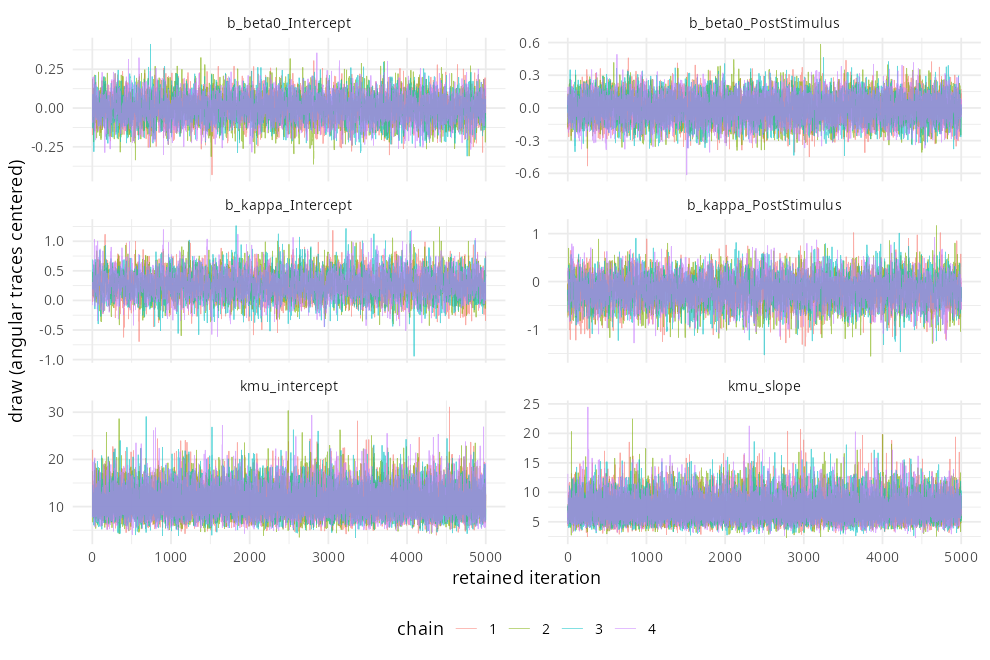

In [9]:
trace_parameters <- c("b_beta0_Intercept", "b_beta0_PostStimulus",
  "b_kappa_Intercept", "b_kappa_PostStimulus", "kmu_intercept", "kmu_slope")

p_trace <- trace_plot(fit, trace_parameters, circular_parameters)
save_figure(p_trace, "trace", 9, 6)


## 4. Posterior directions and concentration

Evaluate every track in both conditions. The individual mean-direction
panel and the within-individual $R(\kappa)$ panel include 95% HDIs.
Directions are combined with circular arithmetic; concentration is
evaluated on the natural scale after softplus.


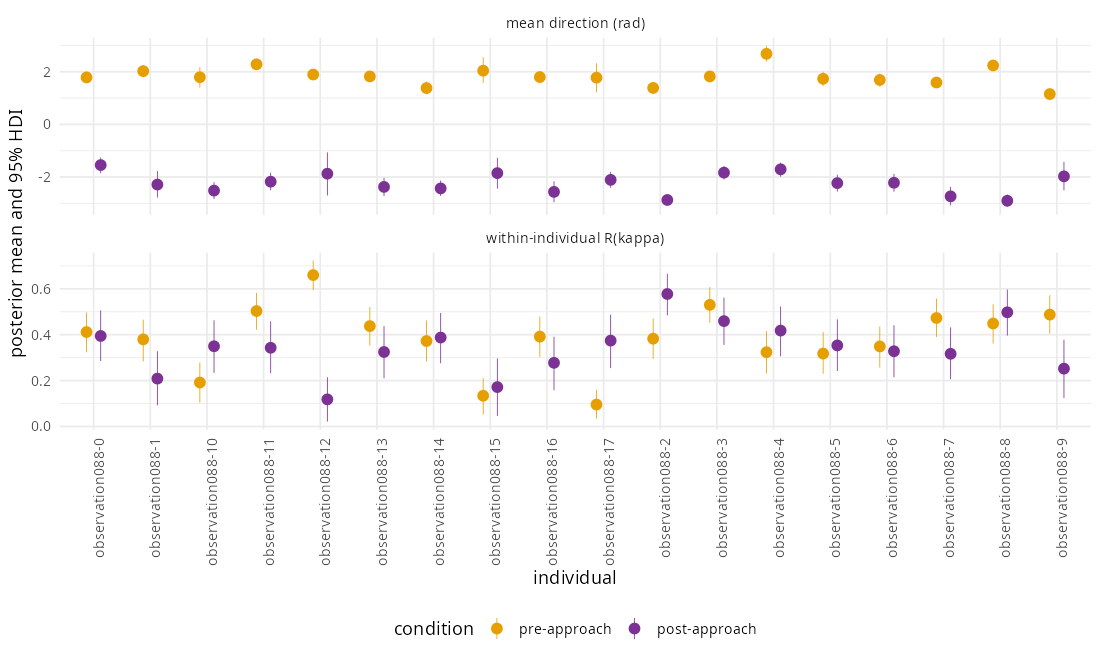

In [10]:


# Draw x individual-condition matrices from the fitted model; the
# per-draw direction and concentration matrices feed the summary panels,
# the alignment statistic and the PPC below (twin of zebra_posthoc.py).
posterior <- posterior_directions(fit, data, condition_labels)
prediction_data <- posterior$prediction_data
mu <- posterior$mu
kappa <- posterior$kappa
J <- posterior$J
pre <- posterior$pre
post <- posterior$post
group_alignment <- posterior$group_alignment
individual_summary <- posterior$individual_summary
p_individual <- individual_plot(individual_summary, condition_colors)
save_figure(p_individual, "individual_posteriors", 10, 6)


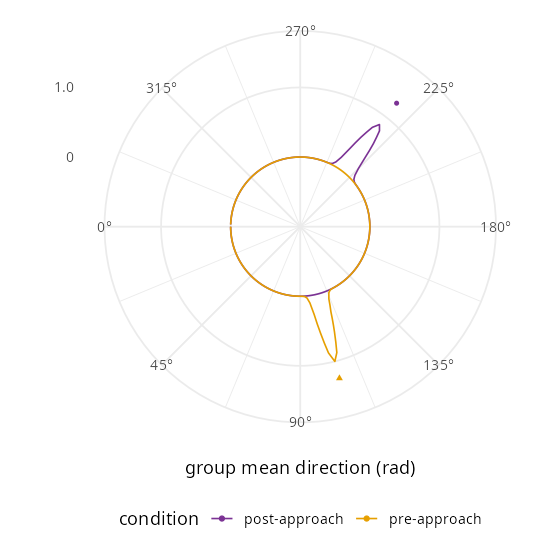

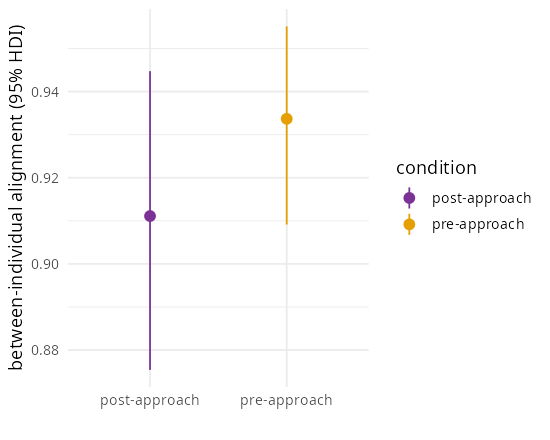

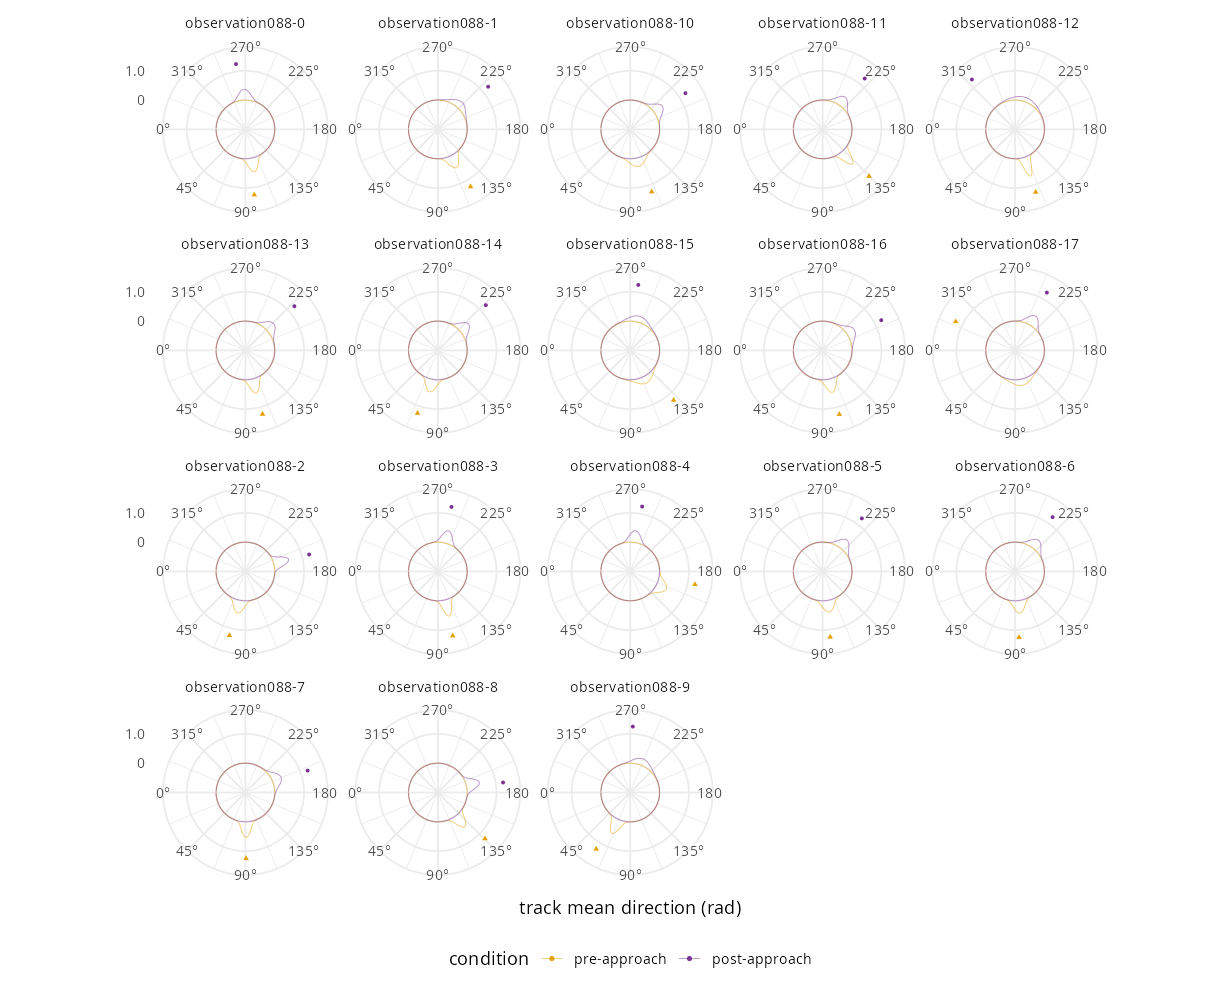

In [11]:
# As in Python's main summary, group direction here is the equal-track
# circular mean of conditional track directions. The PPC below instead
# uses population fixed effects for its group-direction comparison.
group_mu <- cbind(apply(mu[, pre, drop = FALSE], 1, circ_mean),
                   apply(mu[, post, drop = FALSE], 1, circ_mean))
# Polar KDE panels follow the Python twin (zebra_plots.py, plot_summary):
# the plotted radius is 1 + kde/max_kde, where max_kde is the shared peak
# of all group and per-track curves; the inner ring (radius 1, labelled
# "0") therefore sits at density zero instead of the origin, the outer
# ring (radius 2, "1.0") at the shared peak. 0 degrees is at the top and
# the angle axis runs clockwise with a label every 45 degrees;
# empirical circular means sit at fixed radius 2.25, away from the curves.
theta <- seq(-pi, pi, length.out = 201)
group_kde <- do.call(rbind, lapply(1:2, function(c) {
  data.frame(theta = theta %% (2 * pi),
    density = vapply(theta, function(t) mean(exp(vm_logpdf(t, group_mu[, c], 500))), numeric(1)),
    condition = condition_labels[c])
}))
track_kde <- do.call(rbind, lapply(seq_len(nrow(prediction_data)), function(j) {
  data.frame(theta = theta %% (2 * pi),
    density = vapply(theta, function(t) mean(exp(vm_logpdf(t, mu[, j], 300))), numeric(1)),
    Track = prediction_data$Track[j], condition = prediction_data$condition[j])
}))
max_kde <- max(group_kde$density, track_kde$density)
group_kde$r <- 1 + group_kde$density / max_kde
track_kde$r <- 1 + track_kde$density / max_kde
empirical_group <- do.call(rbind, lapply(1:2, function(c) data.frame(
  theta = circ_mean(group_mu[, c]) %% (2 * pi), r = 2.25,
  condition = condition_labels[c],
  shape = if (c == 2L) "filled circle" else "filled square")))
p_group_mu <- polar_direction_plot(group_kde, empirical_group,
  "group mean direction (rad)", condition_colors)
save_figure(p_group_mu, "group_direction", 5, 5)
alignment_df <- do.call(rbind, lapply(1:2, function(c) {
  data.frame(condition = condition_labels[c],
    as.list(interval_row(group_alignment[, c])))
}))
p_alignment <- alignment_plot(alignment_df, condition_colors)
save_figure(p_alignment, "group_alignment", 5, 4)

# Per-track polar direction posteriors, with empirical circular means.
empirical <- do.call(rbind, lapply(split(data, list(data$Track, data$condition),
  drop = TRUE), function(g) data.frame(Track = g$Track[1],
    condition = g$condition[1], theta = circ_mean(g$HeadingRadians) %% (2 * pi),
    r = 2.25,
    shape = if (g$condition[1] == condition_labels[2]) "filled circle" else
      "filled square")))
p_track_mu <- polar_direction_plot(track_kde, empirical,
  "track mean direction (rad)", condition_colors, track = TRUE)
save_figure(p_track_mu, "track_direction_polar", 11, 9)


## Posterior predictive checks

The first predictive check compares hierarchical bootstraps of the
observations with posterior response-parameter summaries: group mean
direction, between-individual alignment, and each individual's direction
and within-individual concentration. Resample individuals first, then
trials/windows within each condition. Open markers show data bootstraps;
filled markers show the posterior, with 95% HDIs. The group mean panel
uses the fixed direction effects.


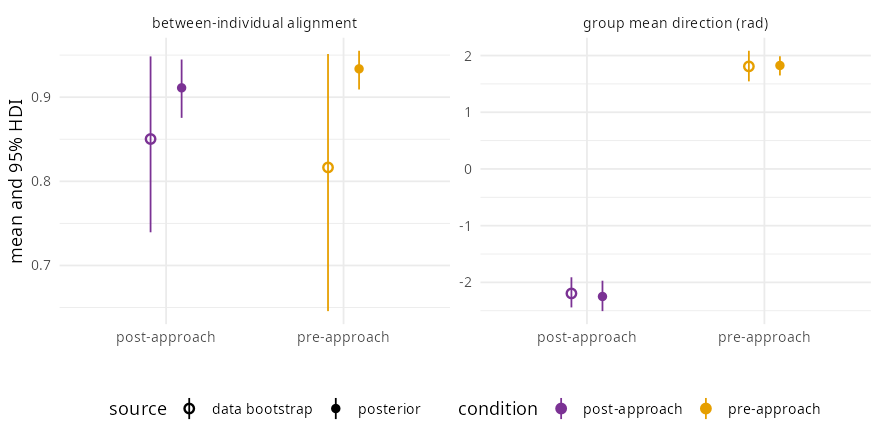

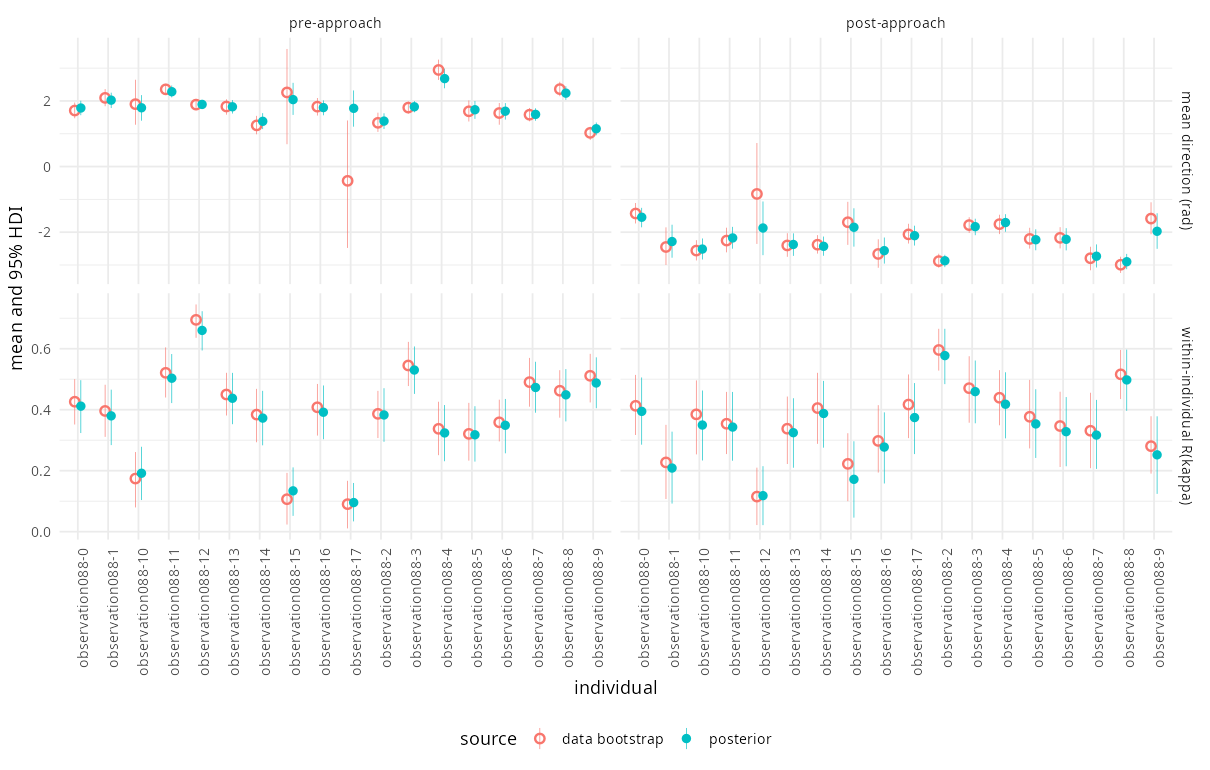

In [12]:
# Python's supplemental PPC compares data bootstraps with fitted response
# parameters (not with a new stochastic dataset). Reproduce that check,
# then add a conventional replicated-data check below.
B_GROUP <- if (quick_run) 200L else 2000L
B_INDIV <- if (quick_run) 150L else 1500L
ys <- lapply(seq_len(nrow(prediction_data)), function(j) {
  data$HeadingRadians[as.character(data$Track) ==
    as.character(prediction_data$Track[j]) &
    data$PostStimulus == prediction_data$PostStimulus[j]]
})
stopifnot(all(lengths(ys) > 0L))
# The data-bootstrap vs posterior comparison (Python's supplemental PPC)
# runs in the sourced posthoc script; the seed stays here.
set.seed(SEED + 10L)
ppc_boot <- ppc_bootstrap_stats(fit, prediction_data, ys, J,
  B_GROUP, B_INDIV, condition_labels, group_alignment, individual_summary)
p_group_ppc <- group_ppc_plot(ppc_boot$ppc_group, condition_colors)
save_figure(p_group_ppc, "ppc_group", 8, 4)

p_ind_ppc <- individual_ppc_plot(ppc_boot$ppc_individual)
save_figure(p_ind_ppc, "ppc_individual", 11, 7)


A second check draws replicated angles from each individual's fitted
likelihood at the original sample sizes. It compares resultant lengths
of observed and replicated samples. This captures finite-sample scatter
as well as uncertainty in the response parameters.


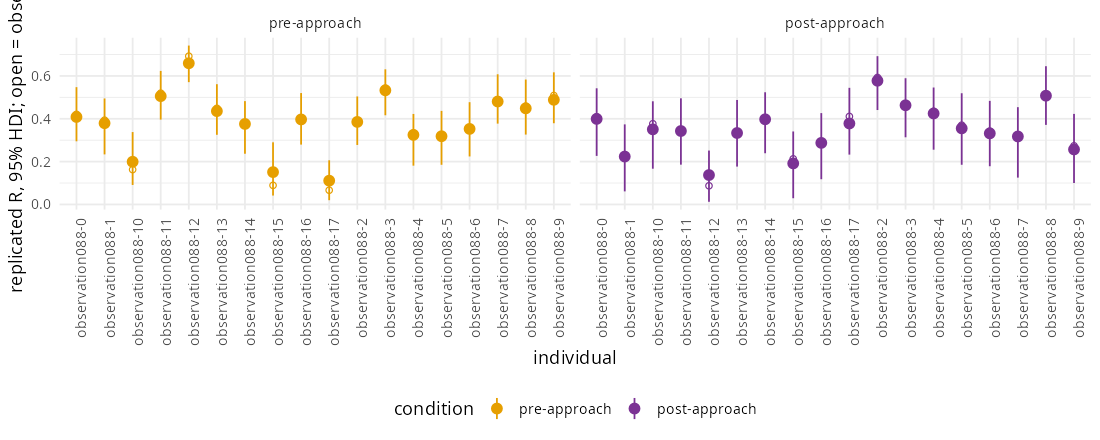

In [13]:
# Same observed sample sizes, each animal's own conditional likelihood.
# Limit simulation draws only; MCMC fitting still uses the budgets above.
set.seed(SEED + 20L)
draw_ids <- sample.int(nrow(mu), min(nrow(mu), if (quick_run) 100L else 400L))
rep_stats <- replicated_stats(mu, kappa, ys, draw_ids, prediction_data)
p_replicates <- replicated_r_plot(rep_stats, condition_colors)
save_figure(p_replicates, "ppc_replicated", 10, 4)
